# Loading data

In [1]:
import pandas as pd
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt

project_root = Path("..")

# Notebook is located under 10_code
project_root = Path("..")

# Left file 2000-2010
input_path = project_root / "00_data" / "processed" / "master_county_year_panel.csv"

# load the data
df = pd.read_csv(input_path)

df

,state,county,year,population,total_pills,total_mme,n_transactions,drug_deaths,missing_deaths,mme_per_capita,...,log_overdoses_per_100k,is_FL,is_WA,group_FL,group_WA,treated,post,t_minus_policy,county_fe,year_fe
0,AL,AUTAUGA,2006,51328,2.850573e+06,5.166274e+07,8838.0,NaN,1,1006.521665,...,NaN,0,0,control_FL,other,0,0,NaN,AL_AUTAUGA,2006
1,AL,BALDWIN,2006,168121,8.586086e+06,1.628179e+08,30450.0,11.0,0,968.456784,...,2.020608,0,0,control_FL,other,0,0,NaN,AL_BALDWIN,2006
2,AL,BARBOUR,2006,27861,1.018382e+06,1.169558e+07,4356.0,NaN,1,419.783224,...,NaN,0,0,control_FL,other,0,0,NaN,AL_BARBOUR,2006
3,AL,BIBB,2006,22099,9.624879e+05,1.658575e+07,3270.0,NaN,1,750.520260,...,NaN,0,0,control_FL,other,0,0,NaN,AL_BIBB,2006
4,AL,BLOUNT,2006,55485,1.590574e+06,2.555605e+07,4541.0,NaN,1,460.593891,...,NaN,0,0,control_FL,other,0,0,NaN,AL_BLOUNT,2006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5215,WA,WAHKIAKUM,2015,4035,1.322830e+05,1.670586e+06,553.0,NaN,1,414.023840,...,NaN,0,1,other,treated_WA,1,1,3.0,WA_WAHKIAKUM,2015
5216,WA,WALLA WALLA,2015,59726,5.353771e+06,8.184576e+07,14808.0,NaN,1,1370.354030,...,NaN,0,1,other,treated_WA,1,1,3.0,WA_WALLA WALLA,2015
5217,WA,WHATCOM,2015,207100,9.873313e+06,2.436225e+08,33041.0,23.0,0,1176.352199,...,2.493680,0,1,other,treated_WA,1,1,3.0,WA_WHATCOM,2015
5218,WA,WHITMAN,2015,46737,1.692291e+06,2.508456e+07,6608.0,NaN,1,536.717393,...,NaN,0,1,other,treated_WA,1,1,3.0,WA_WHITMAN,2015


###############################################################################################################

# Mortality Part

## 1. Define plot functions (replace NaN value + plot)

In [2]:
def plot_pre_post_with_ci(
    df,
    state_code,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label=None,
    nan_strategy="drop",
):
    """
    Pre-Post plot with linear trends and 95% CI.
    Now includes multiple NaN handling strategies:
    'drop', 'mean', 'median', 'ffill', 'bfill', 'interpolate'.
    """

    if state_label is None:
        state_label = state_code

    # 1. keep only the selected state
    df_state = df[df["state"] == state_code].copy()

    # -----------------------------------------
    # 2. NaN Handling BEFORE aggregation
    # -----------------------------------------
    if nan_strategy == "mean":
        df_state[rate_col] = df_state[rate_col].fillna(df_state[rate_col].mean())

    elif nan_strategy == "median":
        df_state[rate_col] = df_state[rate_col].fillna(df_state[rate_col].median())

    elif nan_strategy == "ffill":
        df_state[rate_col] = df_state[rate_col].ffill()

    elif nan_strategy == "bfill":
        df_state[rate_col] = df_state[rate_col].bfill()

    elif nan_strategy == "interpolate":
        df_state = df_state.sort_values("year")
        df_state[rate_col] = df_state[rate_col].interpolate(method="linear")

    elif nan_strategy == "drop":
        pass  # drop will happen naturally later

    else:
        raise ValueError("Invalid nan_strategy choice.")

    # 3. aggregate to state-year
    state_year = (
        df_state.groupby("year", as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
    )

    # after aggregation, drop remaining NAs (if any)
    state_year = state_year.dropna(subset=["rate"])

    # 4. split into pre/post periods
    pre_mask = (state_year["year"] >= policy_year - pre_window) & (
        state_year["year"] < policy_year
    )
    post_mask = (state_year["year"] >= policy_year) & (
        state_year["year"] <= policy_year + post_window
    )

    pre = state_year[pre_mask].copy()
    post = state_year[post_mask].copy()

    if pre.empty or post.empty:
        print(f"Not enough data for {state_label} around {policy_year}.")
        return

    # helper: linear regression + CI
    def fit_trend(seg):
        seg = seg.dropna(subset=["rate"])
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    pre_pred, pre_low, pre_high = fit_trend(pre)
    post_pred, post_low, post_high = fit_trend(post)

    # 5. plot
    plt.figure(figsize=(10, 4))

    x_pre = pre["year"].to_numpy()
    x_post = post["year"].to_numpy()

    plt.plot(x_pre, pre_pred, color="blue", label=f"Pre-Policy ({nan_strategy})")
    plt.fill_between(x_pre, pre_low, pre_high, alpha=0.15, color="blue")

    plt.plot(x_post, post_pred, color="red", label="Post-Policy")
    plt.fill_between(x_post, post_low, post_high, alpha=0.15, color="red")

    plt.axvline(policy_year, color="orange", linestyle="--")

    plt.title(
        f"Pre-Post Policy Analysis for {state_label} ({nan_strategy} NaN handling)"
    )
    plt.xlabel("Year")
    plt.ylabel(rate_col)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Compare different NaN value dealing ways (bigger plots)

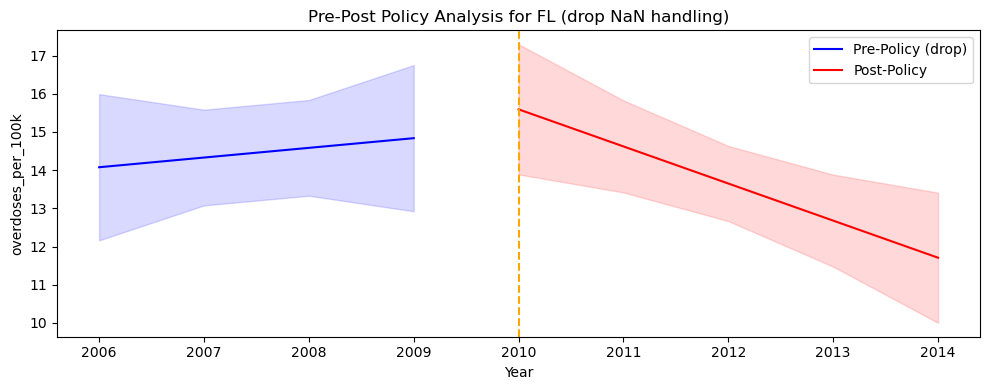

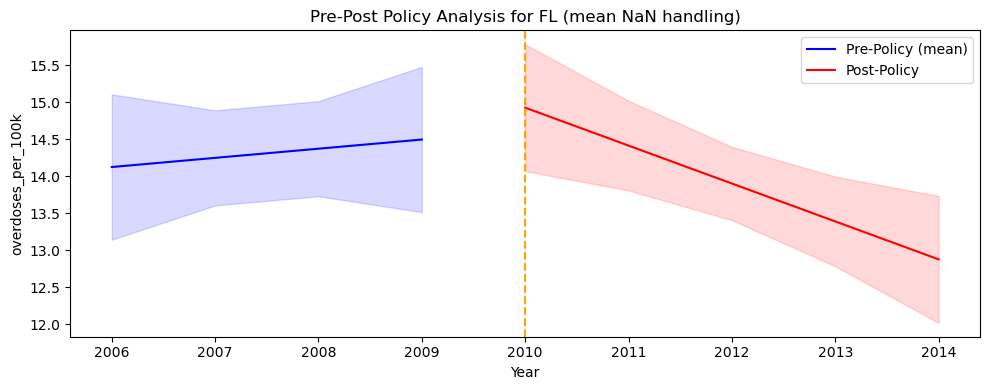

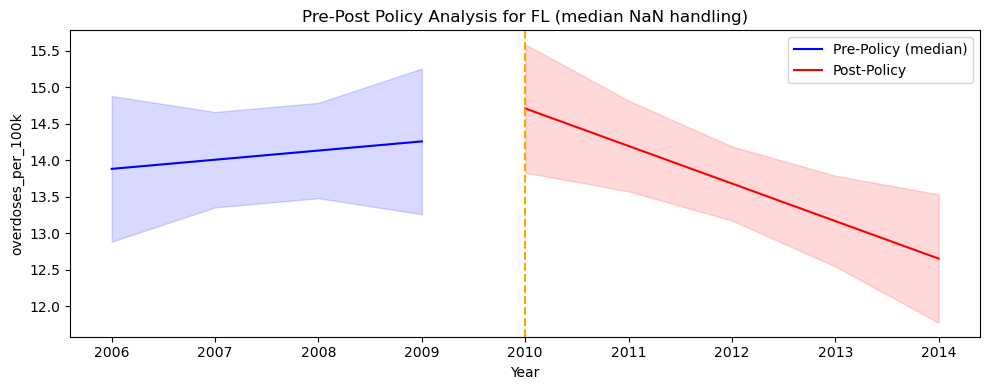

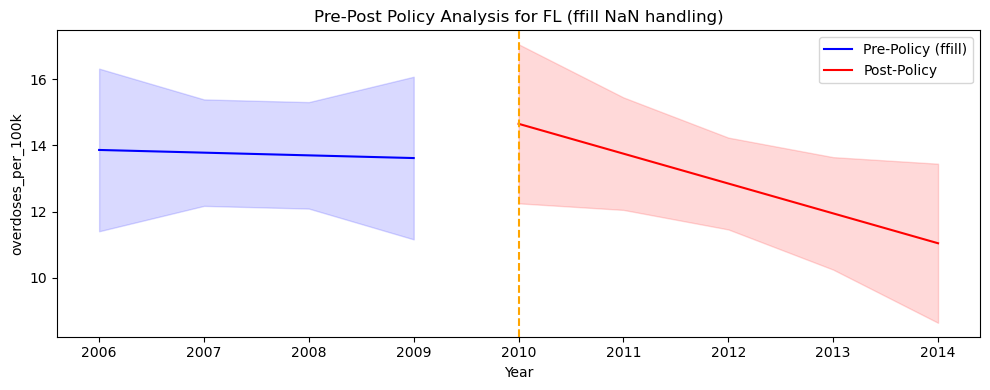

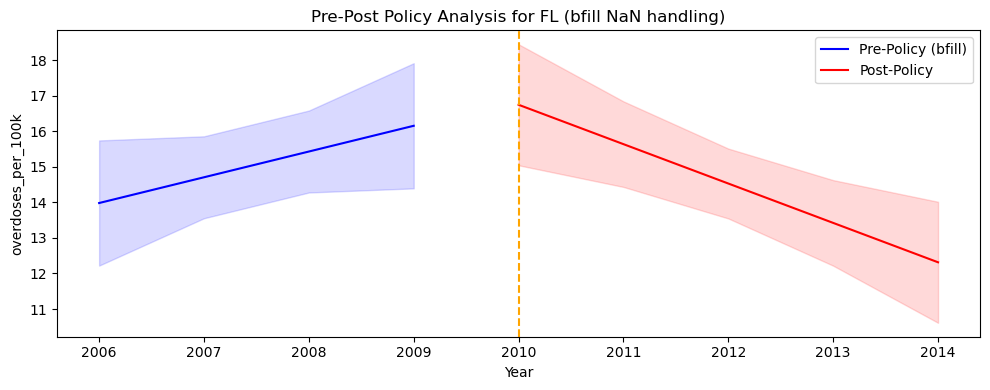

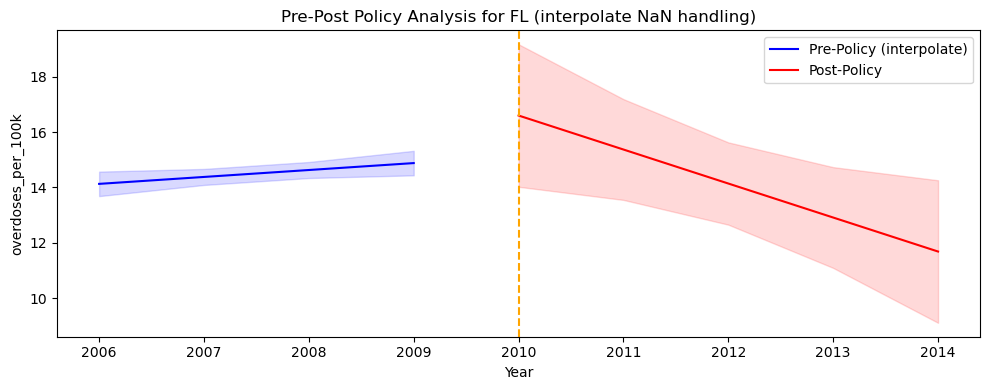

In [3]:
# Florida
# 1. drop
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="drop"
)

# 2. mean
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="mean"
)

# 3. median
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="median"
)

# 4. ffill
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="ffill"
)

# 5. bfill
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="bfill"
)

# 6. interpolate
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="interpolate"
)

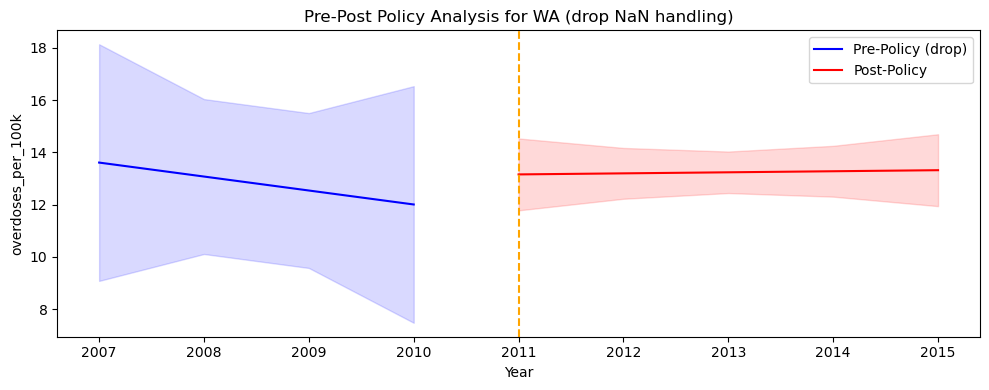

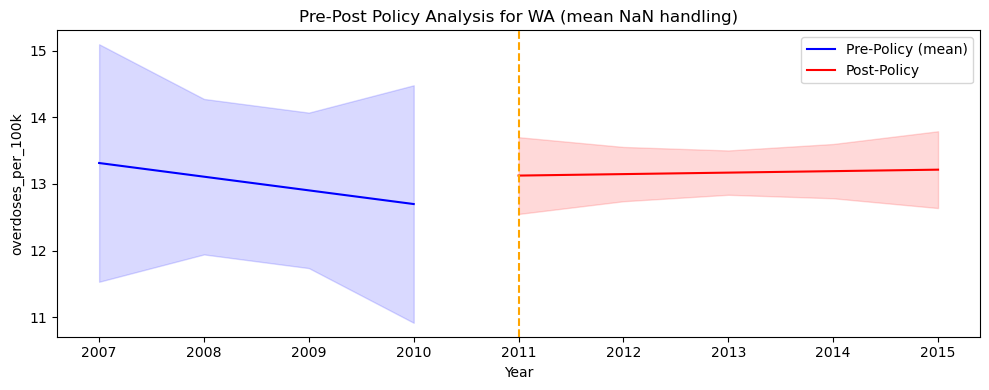

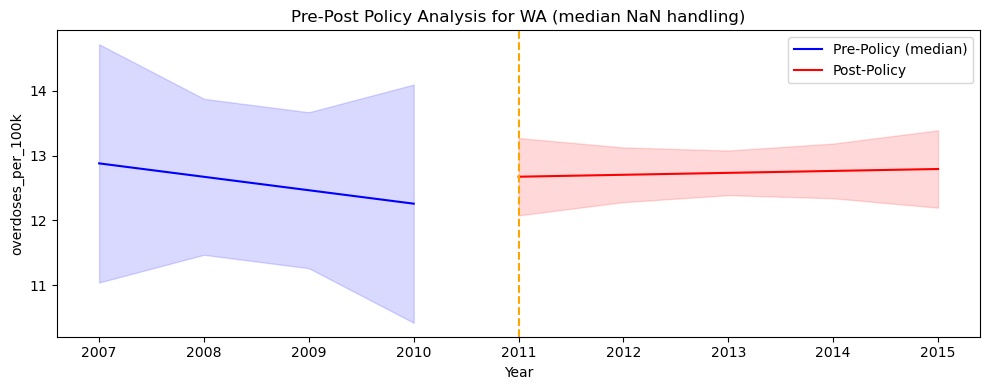

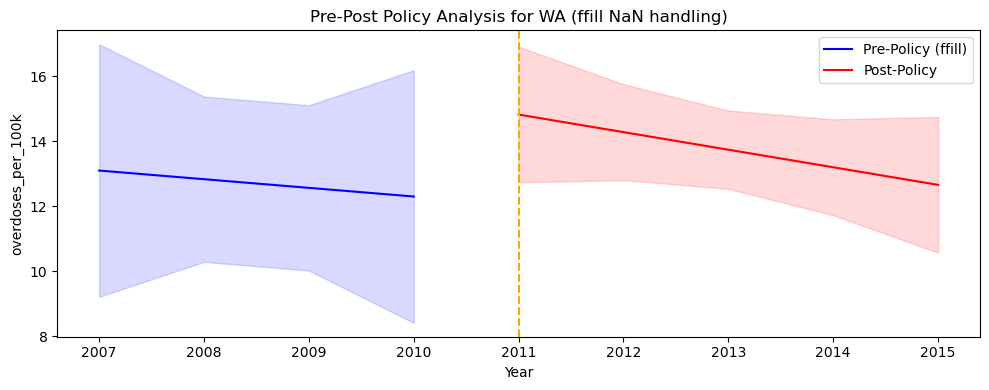

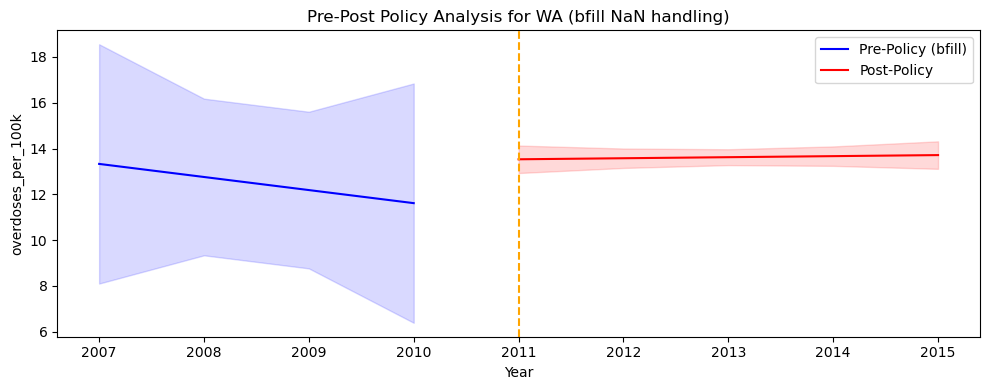

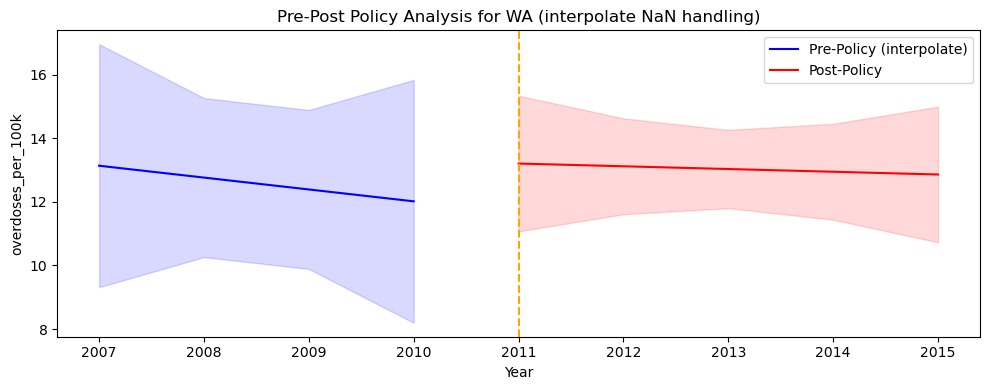

In [4]:
# Washington
# 1. drop
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="drop"
)

# 2. mean
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="mean"
)

# 3. median
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="median"
)

# 4. ffill
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="ffill"
)

# 5. bfill
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="bfill"
)

# 6. interpolate
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="interpolate"
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [30]:
import matplotlib.pyplot as plt


def plot_pre_post_grid(
    df,
    state_code,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
):
    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    # ensure y-scale consistent across all plots
    all_values = df[df["state"] == state_code][rate_col].dropna()
    y_min, y_max = all_values.min(), all_values.max()

    for i, strat in enumerate(strategies):
        ax = axes[i]

        # run the existing function but draw into ax instead of new figure
        df_state = df[df["state"] == state_code].copy()

        # ----- handle NaN -----
        if strat != "drop":
            df_state = df_state.sort_values("year")
            g = df_state.groupby("state")

            if strat == "mean":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.fillna(s.mean()))
            elif strat == "median":
                df_state[rate_col] = g[rate_col].transform(
                    lambda s: s.fillna(s.median())
                )
            elif strat == "ffill":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.ffill())
            elif strat == "bfill":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.bfill())
            elif strat == "interpolate":
                df_state[rate_col] = g[rate_col].transform(lambda s: s.interpolate())

        # ----- aggregate to state-year -----
        state_year = (
            df_state.groupby("year", as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        # ----- split pre/post -----
        pre = state_year[
            (state_year["year"] >= policy_year - pre_window)
            & (state_year["year"] < policy_year)
        ]
        post = state_year[
            (state_year["year"] >= policy_year)
            & (state_year["year"] <= policy_year + post_window)
        ]

        # fit OLS helper
        def fit_segment(seg):
            X = sm.add_constant(seg["year"])
            m = sm.OLS(seg["rate"], X).fit()
            p = m.get_prediction(X)
            return p.predicted_mean, p.conf_int()[:, 0], p.conf_int()[:, 1]

        pre_mean, pre_low, pre_high = fit_segment(pre)
        post_mean, post_low, post_high = fit_segment(post)

        # ----- plot in the given axis -----
        ax.plot(pre["year"], pre_mean, color="blue")
        ax.fill_between(pre["year"], pre_low, pre_high, color="blue", alpha=0.15)

        ax.plot(post["year"], post_mean, color="red")
        ax.fill_between(post["year"], post_low, post_high, color="red", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(f"{strat}", fontsize=12)
        ax.set_ylim(y_min, y_max)  # same y-axis for comparability
        ax.set_xlabel("Year")
        ax.set_ylabel("Rate")

    fig.suptitle(f"{state_code}: Pre-Post Comparison (6 NaN Strategies)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

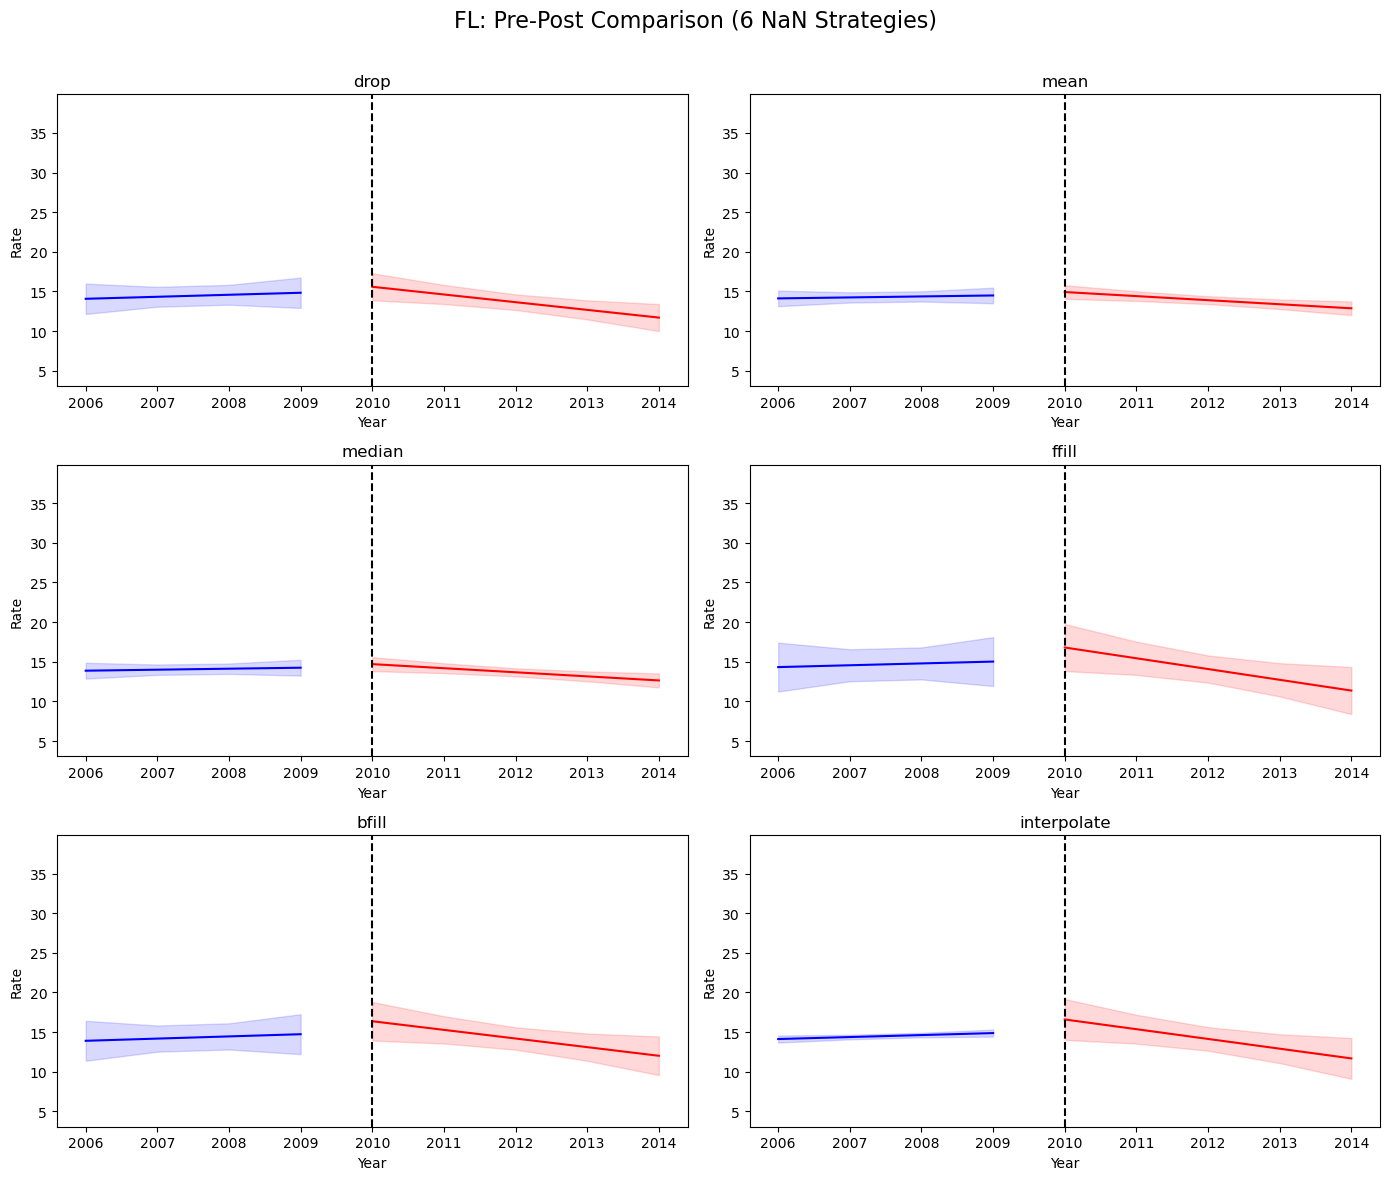

In [ ]:
# Florida
plot_pre_post_grid(df, "FL", 2010, rate_col="overdoses_per_100k")

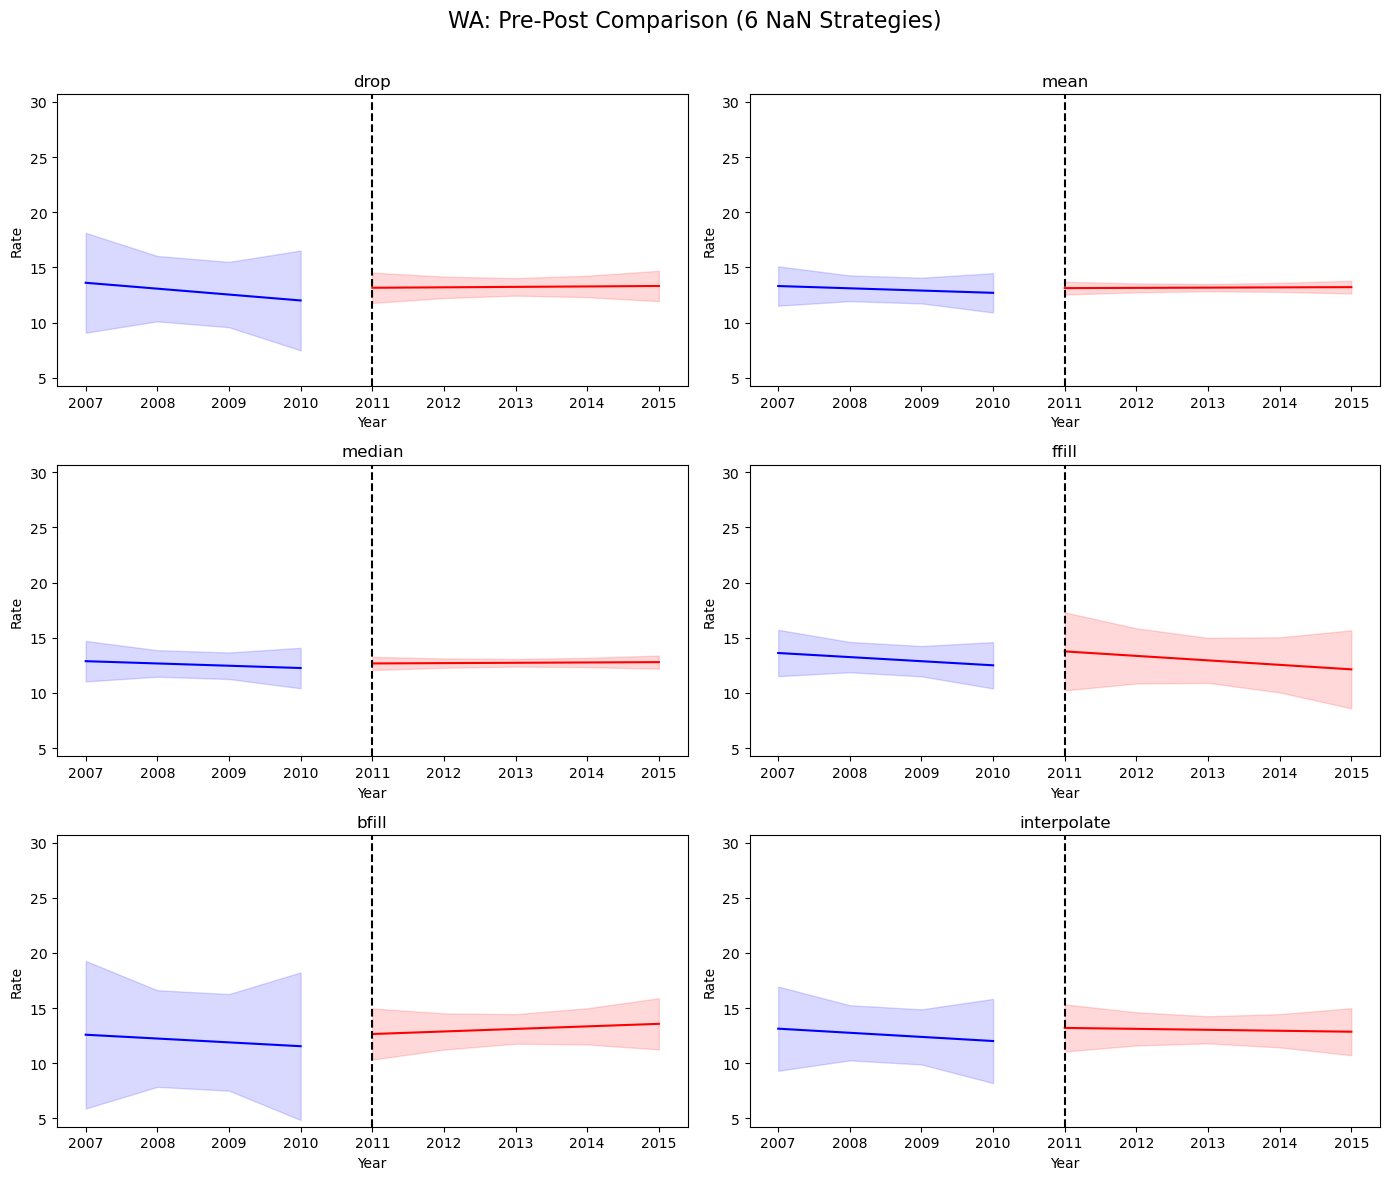

In [42]:
# Washington
plot_pre_post_grid(df, "WA", 2011, rate_col="overdoses_per_100k")

## 4. Final Result (for Mortality) (Pending now)

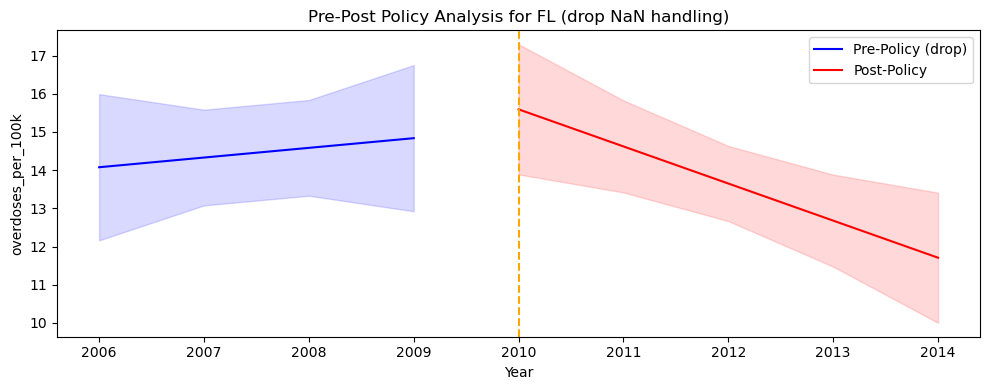

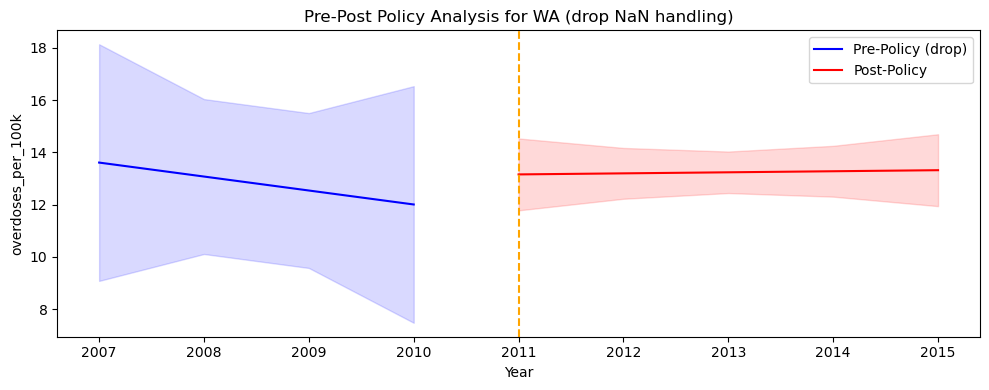

In [5]:
# Florida: policy year 2010, use 2006–2009 vs 2010–2014
plot_pre_post_with_ci(
    df,
    state_code="FL",
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label="FL",
)

# Washington: policy year 2011, use 2007–2010 vs 2011–2015
plot_pre_post_with_ci(
    df,
    state_code="WA",
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label="WA",
)

###############################################################################################################

# Shipment part

## 1. Define plot functions (replace NaN value + plot)

In [6]:
def plot_pre_post_shipment(
    df,
    state_code,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
    nan_strategy="drop",
):
    """
    Pre-Post plot for shipment (e.g., MME per capita) with linear trends and 95% CI.
    NaN strategies:
      - "drop": leave NaN as is (they will be dropped after aggregation)
      - "mean": fill NaN with the state-specific mean
      - "median": fill NaN with the state-specific median
      - "ffill": forward fill within each state (sorted by year)
      - "bfill": backward fill within each state (sorted by year)
      - "interpolate": linear interpolation within each state (sorted by year)
    """

    # Keep one state
    data = df[df["state"] == state_code].copy()

    # ---- NaN handling at raw-row level for this state ----
    if nan_strategy != "drop":
        data = data.sort_values("year")

        if nan_strategy == "mean":
            data[rate_col] = data[rate_col].fillna(data[rate_col].mean())
        elif nan_strategy == "median":
            data[rate_col] = data[rate_col].fillna(data[rate_col].median())
        elif nan_strategy == "ffill":
            data[rate_col] = data[rate_col].ffill()
        elif nan_strategy == "bfill":
            data[rate_col] = data[rate_col].bfill()
        elif nan_strategy == "interpolate":
            data[rate_col] = data[rate_col].interpolate(method="linear")
        else:
            raise ValueError("Invalid nan_strategy choice.")

    # Aggregate to state-year
    yearly = (
        data.groupby("year", as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
        .dropna(subset=["rate"])
    )

    # Split into pre/post
    pre = yearly[
        (yearly["year"] >= policy_year - pre_window) & (yearly["year"] < policy_year)
    ]
    post = yearly[
        (yearly["year"] >= policy_year) & (yearly["year"] <= policy_year + post_window)
    ]

    if pre.empty or post.empty:
        print(
            f"Not enough data for {state_code} around {policy_year} ({nan_strategy})."
        )
        return

    # Fit regression with CI
    def fit_with_ci(seg):
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    pre_mean, pre_low, pre_high = fit_with_ci(pre)
    post_mean, post_low, post_high = fit_with_ci(post)

    # Plot
    plt.figure(figsize=(10, 4))

    # Pre-policy (red)
    plt.plot(
        pre["year"],
        pre_mean,
        color="red",
        label=f"Pre-Policy ({policy_year-pre_window}–{policy_year-1})",
    )
    plt.fill_between(pre["year"], pre_low, pre_high, color="red", alpha=0.15)

    # Post-policy (blue)
    plt.plot(
        post["year"],
        post_mean,
        color="blue",
        label=f"Post-Policy ({policy_year}–{policy_year+post_window})",
    )
    plt.fill_between(post["year"], post_low, post_high, color="blue", alpha=0.15)

    # Policy line
    plt.axvline(policy_year, color="black", linestyle="--")

    # Labels and title
    plt.title(
        f"Pre-Post Analysis for shipment ({rate_col}) - {state_code} [{nan_strategy}]"
    )
    plt.ylabel(rate_col)
    plt.xlabel("Year")

    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Compare different NaN value dealing ways (bigger plots)

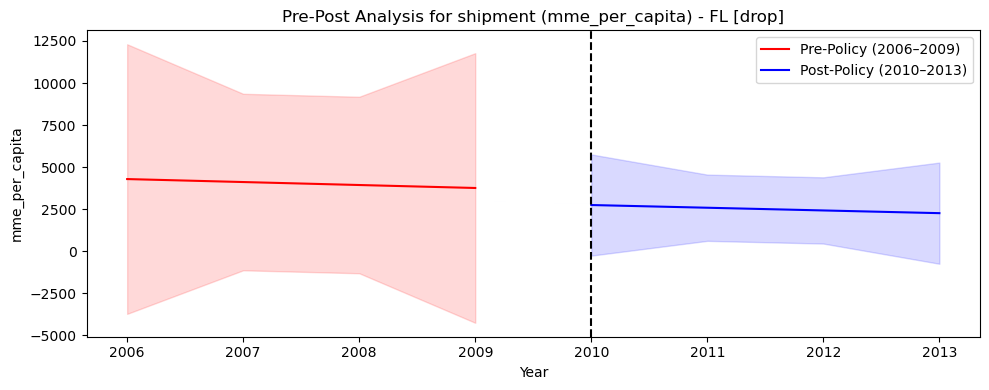

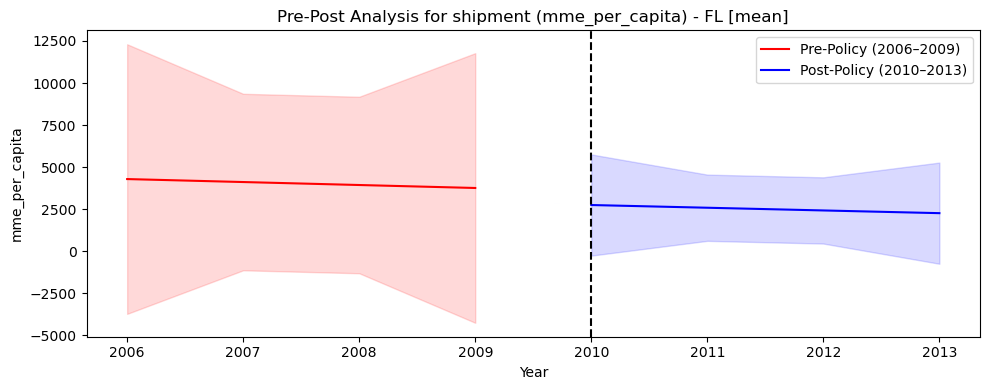

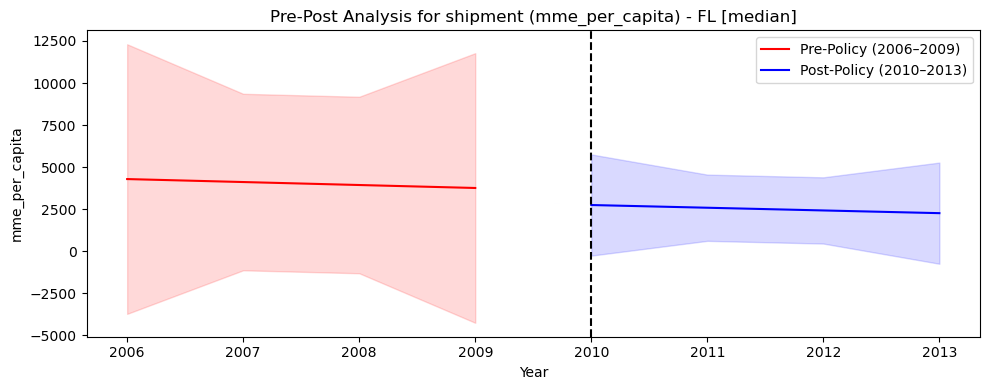

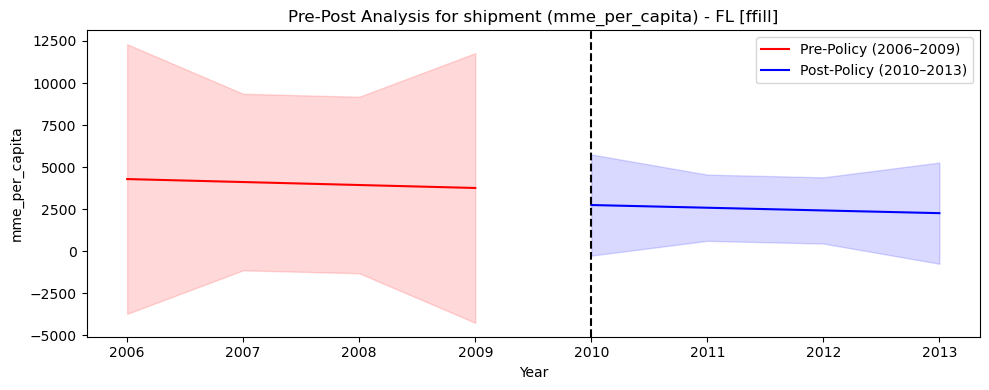

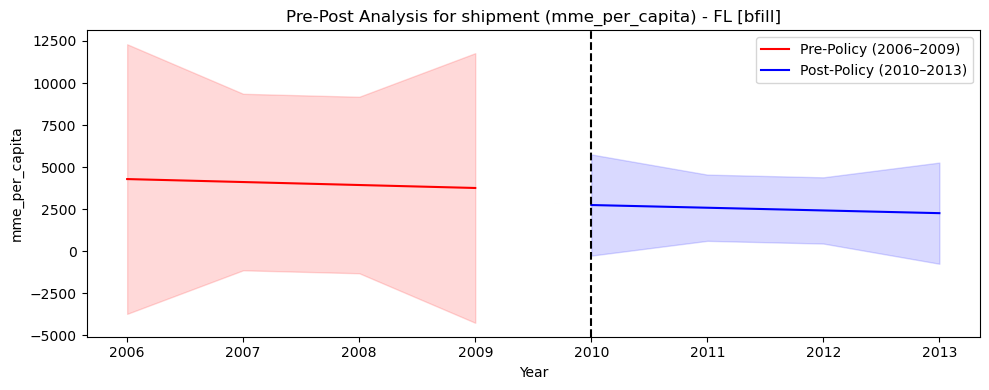

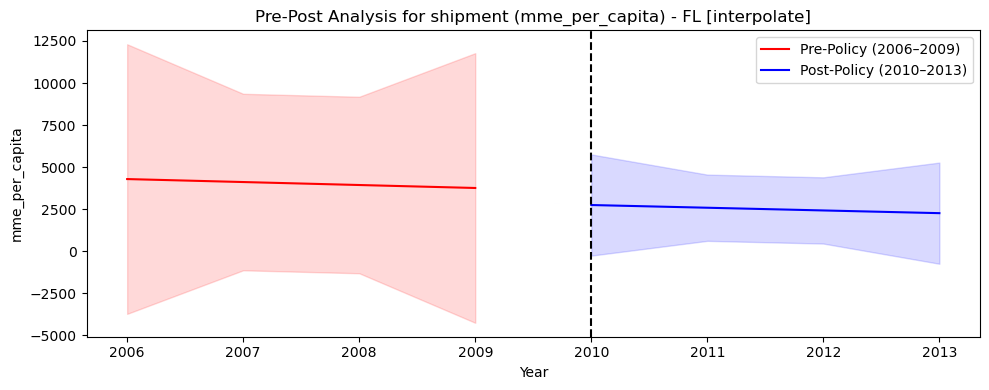

In [7]:
# Florida
# 1. drop
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

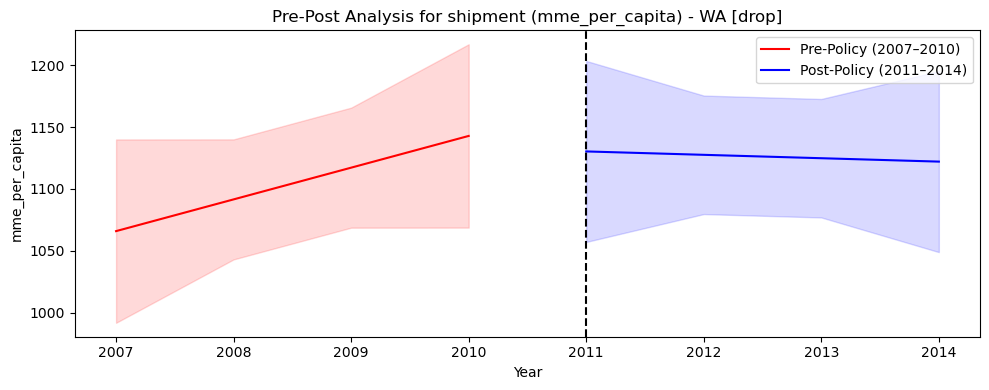

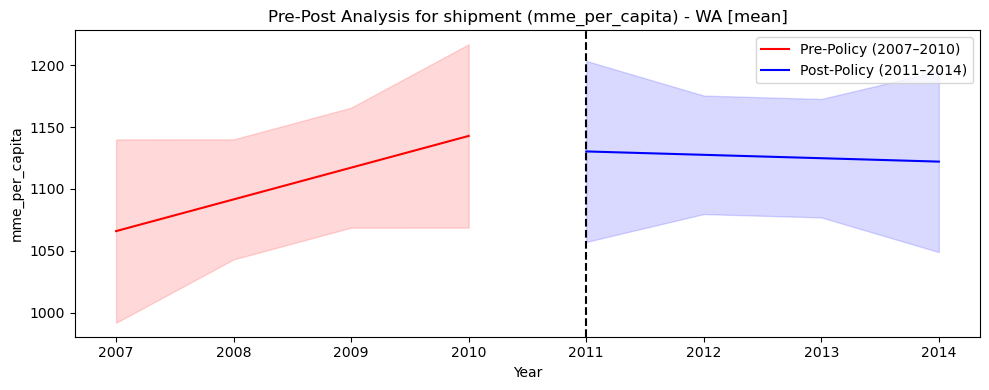

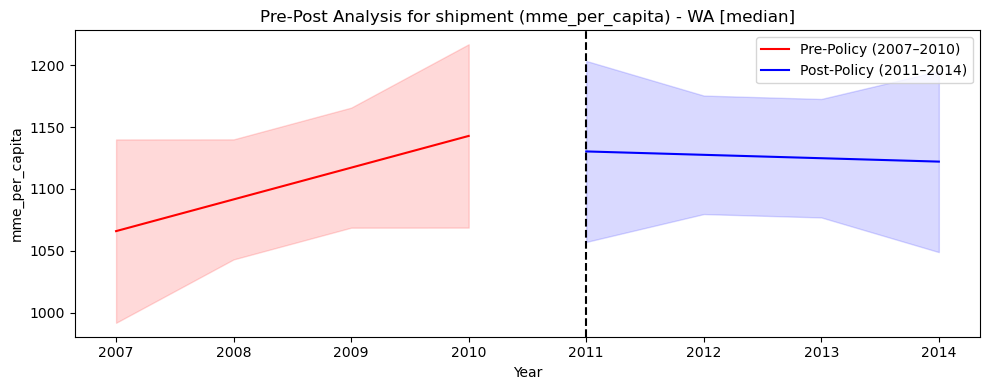

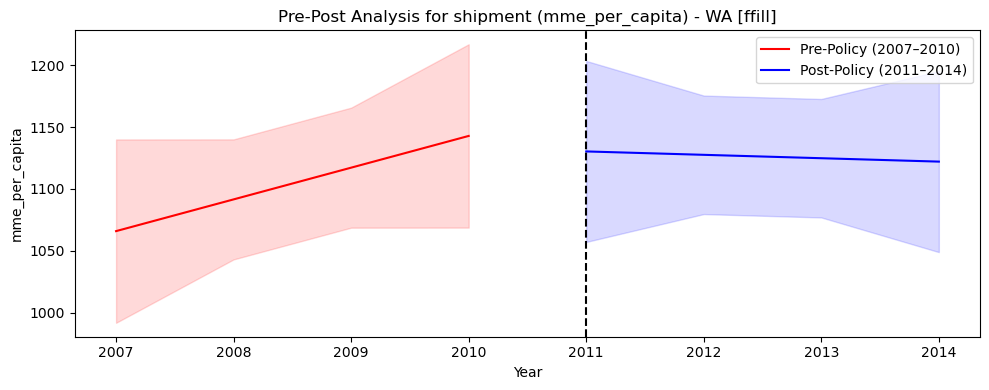

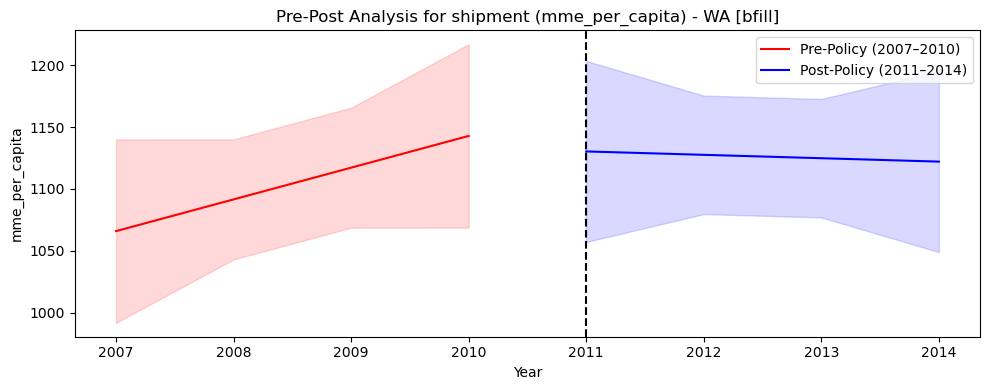

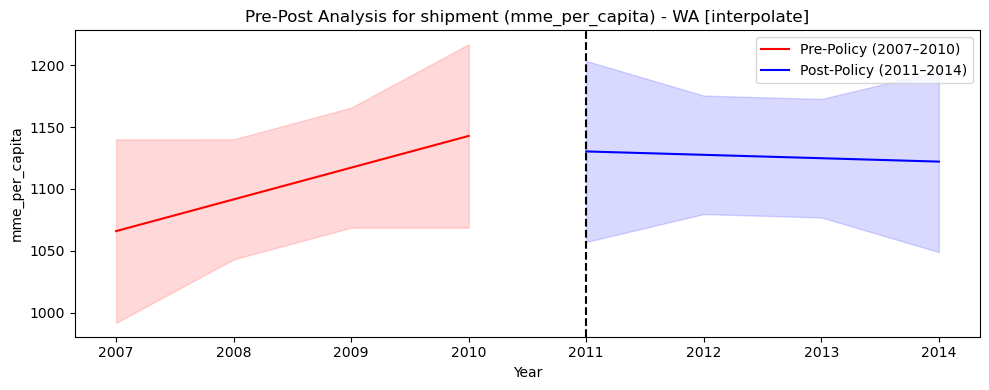

In [8]:
# Washington
# 1. drop
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [ ]:
def plot_pre_post_shipment_grid(
    df,
    state_code,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
):
    """
    Draw 6 pre-post shipment plots (one for each NaN strategy) in a 3x2 grid.
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    data_all = df[df["state"] == state_code].copy()
    if data_all.empty:
        print(f"No data for state {state_code}.")
        return

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    def fit_with_ci(seg):
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    for i, strat in enumerate(strategies):
        ax = axes[i]

        data = data_all.copy()

        if strat != "drop":
            data = data.sort_values("year")

            if strat == "mean":
                data[rate_col] = data[rate_col].fillna(data[rate_col].mean())
            elif strat == "median":
                data[rate_col] = data[rate_col].fillna(data[rate_col].median())
            elif strat == "ffill":
                data[rate_col] = data[rate_col].ffill()
            elif strat == "bfill":
                data[rate_col] = data[rate_col].bfill()
            elif strat == "interpolate":
                data[rate_col] = data[rate_col].interpolate(method="linear")
            else:
                ax.set_title(f"{strat} (invalid strategy)")
                ax.axis("off")
                continue

        # Aggregate to state-year
        yearly = (
            data.groupby("year", as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        # Split pre/post
        pre = yearly[
            (yearly["year"] >= policy_year - pre_window)
            & (yearly["year"] < policy_year)
        ]
        post = yearly[
            (yearly["year"] >= policy_year)
            & (yearly["year"] <= policy_year + post_window)
        ]

        if pre.empty or post.empty:
            ax.set_title(f"{strat} (not enough data)")
            ax.text(
                0.5,
                0.5,
                "Not enough data",
                ha="center",
                va="center",
                transform=ax.transAxes,
                fontsize=10,
            )
            ax.set_axis_off()
            continue

        # regression + CI
        pre_mean, pre_low, pre_high = fit_with_ci(pre)
        post_mean, post_low, post_high = fit_with_ci(post)

        ax.plot(pre["year"], pre_mean, color="red")
        ax.fill_between(pre["year"], pre_low, pre_high, color="red", alpha=0.15)

        ax.plot(post["year"], post_mean, color="blue")
        ax.fill_between(post["year"], post_low, post_high, color="blue", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(strat, fontsize=11)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

    for j in range(len(strategies), len(axes)):
        axes[j].axis("off")

    fig.suptitle(
        f"{state_code} shipment pre-post ({rate_col}) — 6 NaN strategies", fontsize=16
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

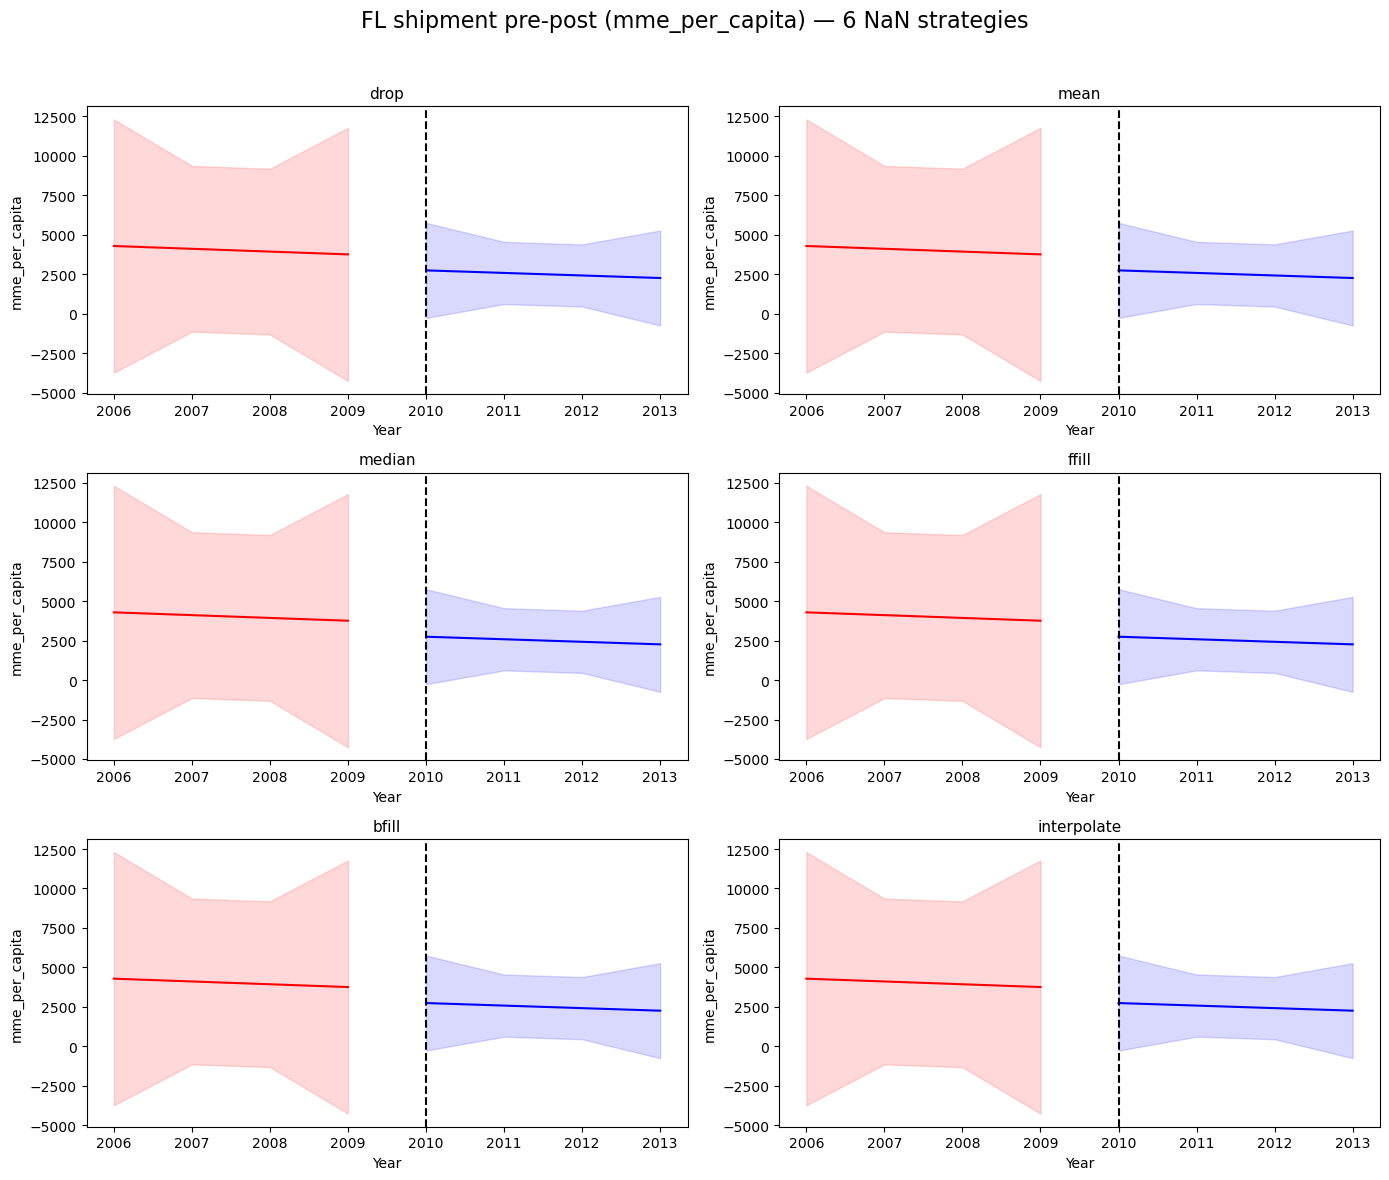

In [18]:
# Florida
plot_pre_post_shipment_grid(
    df,
    state_code="FL",
    policy_year=2010,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
)

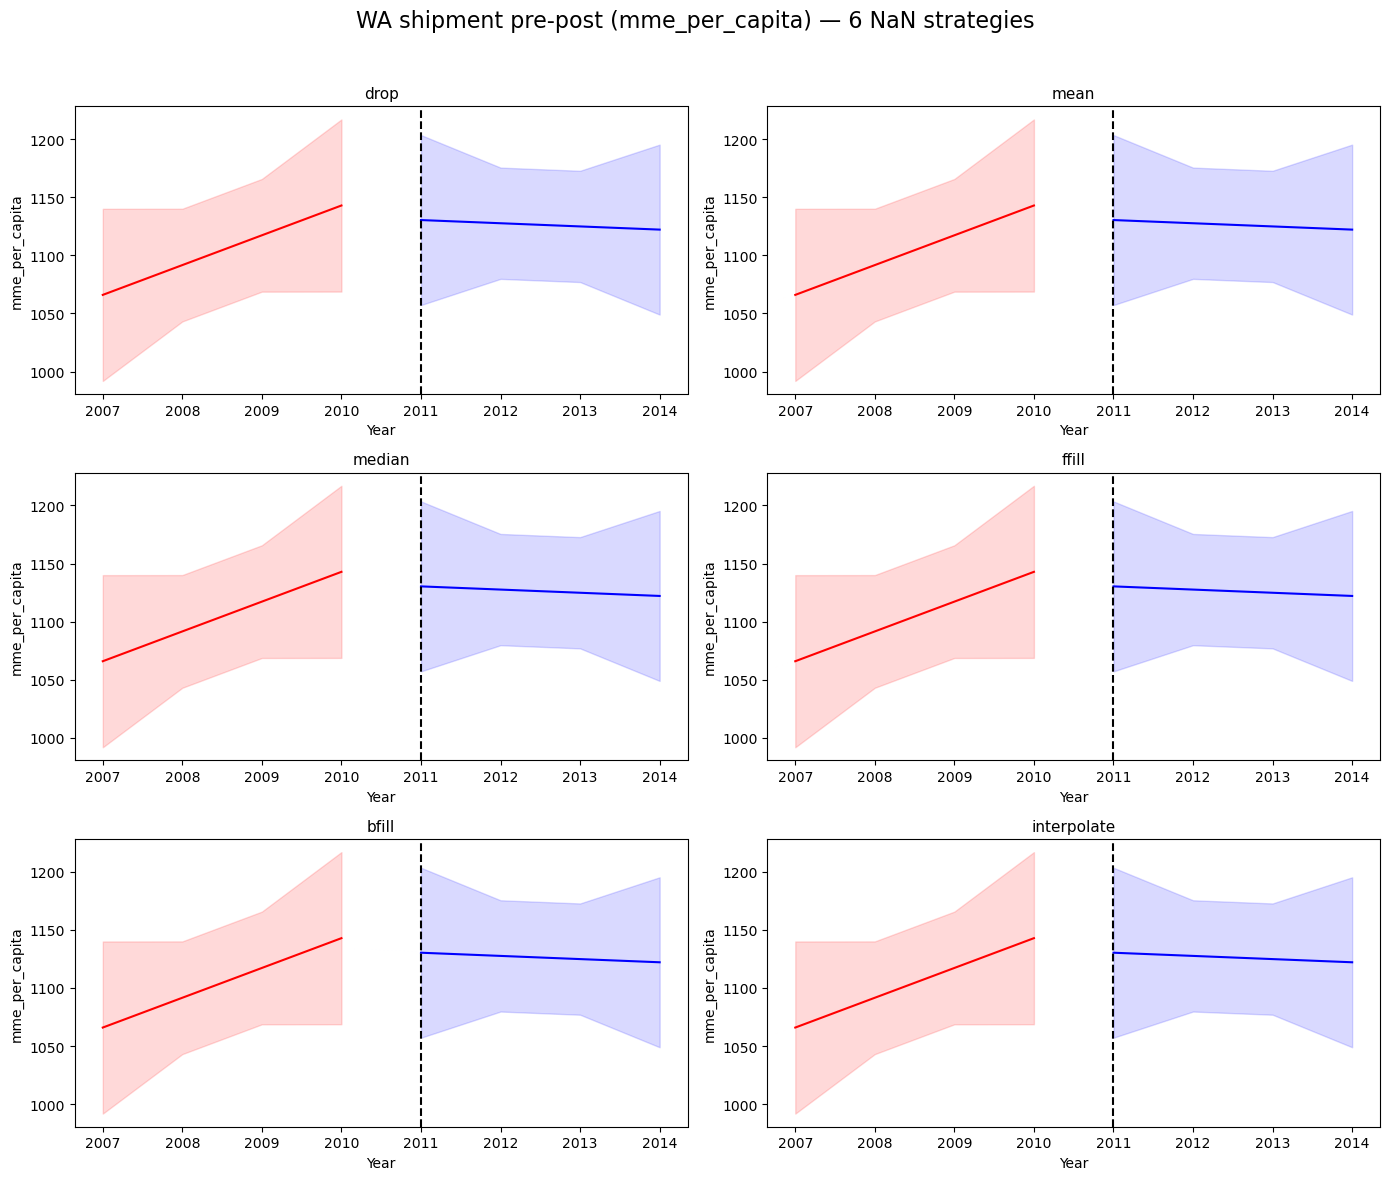

In [19]:
# Washington
plot_pre_post_shipment_grid(
    df,
    state_code="WA",
    policy_year=2011,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
)

## 4. Final Result (for Shipment) (Pending now)